# Predictive Analytics for Bank Risk Assessment & Credit Scoring

## 1. Parameters for Data Analysis & Visualization in Credit Risk Modeling

When analyzing data to select and evaluate algorithms for Credit Risk & Loan Scoring, key parameters to evaluate include:

1. **Target Distribution & Class Balance:**
   * In credit scoring, default rates are typically low (2% - 10%).
   * Visualizing this via count plots indicates whether class rebalancing techniques (like SMOTE or class weights) or specific metrics (like ROC-AUC, Gini, Precision-Recall AUC) are needed instead of standard Accuracy.
2. **Feature Scale & Skewness:**
   * Attributes like `ApplicantIncome`, `LoanAmount`, and `CreditHistory` often display skewed distributions with extreme outliers.
   * Distance-based algorithms (KNN, Logistic Regression with Regularization, Neural Networks) require normalization/standardization,
   * while Tree Ensembles (Random Forest, XGBoost) remain scale-invariant.
3. **Multicollinearity & Feature Correlation:**
   * High correlation among independent variables (e.g., `Debt-to-Income Ratio` vs. `Existing Debt`) causes instability in linear and logistic models.
   * Heatmaps identify redundant features to drop or combine.
4. **Non-Linear Relationships:**
   * Scatter plots and pair plots reveal whether features share linear boundaries with risk scores or non-linear patterns,
   * guiding the decision between Logistic Regression and Tree Ensembles.

---

## 2. Decision Making Based on Outcomes & Visualizations

* **ROC-AUC & Gini Coefficient ($Gini = 2 \times AUC - 1$):**
  * In banking, a model with $AUC > 0.75$ ($Gini > 0.50$) is considered strong for credit scoring.
* **Confusion Matrix & Threshold Tuning:**
  * **False Positives (FP):** Approving a high-risk applicant who defaults (high financial loss).
  * **False Negatives (FN):** Rejecting a creditworthy applicant (lost interest revenue).
  * Because a Default (FP) is much costlier than a Missed Loan (FN), banks lower the approval probability threshold (e.g., from 0.50 to 0.30) to minimize defaults.
* **Residual Analysis (for Continuous Risk Scores):**
  * Checking residual distribution ensures error variance remains uniform across low and high loan amounts.

---

In [16]:
## 3. Python Predictive Analytics Program

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set seed for reproducibility
np.random.seed(42)

In [17]:
# ==============================================================================
# STEP 1: DATA GENERATION & MINING (Create & Load 1000-row CSV)
# ==============================================================================
csv_file = "credit_risk_1000.csv"

# Synthetic generation of 1,000 bank loan applications
income = np.random.normal(loc=55000, scale=18000, size=1000).clip(15000, 150000)
loan_amount = np.random.normal(loc=18000, scale=8000, size=1000).clip(
    2000, 50000
)
credit_score = np.random.normal(loc=650, scale=70, size=1000).clip(300, 850)
dti_ratio = np.random.uniform(5, 50, 1000)  # Debt-to-Income Ratio %
employment_yrs = np.random.exponential(scale=5, size=1000).clip(0, 30)

# Define probability of default based on financial domain logic
default_prob = (
    1 / (1 + np.exp(-(-0.01 * credit_score + 0.05 * dti_ratio - 0.00002 * income + 2.5)))
)
default_label = np.random.binomial(1, default_prob)

df_raw = pd.DataFrame(
    {
        "applicant_income": np.round(income, 2),
        "loan_amount": np.round(loan_amount, 2),
        "credit_score": np.round(credit_score, 0),
        "dti_ratio": np.round(dti_ratio, 2),
        "employment_years": np.round(employment_yrs, 1),
        "loan_default": default_label,  # 1 = High Risk (Default), 0 = Low Risk (Paid)
    }
)

df_raw.to_csv(csv_file, index=False)
print(f"=== STEP 1: CSV File '{csv_file}' generated with {len(df_raw)} records. ===")

# Read CSV input
df = pd.read_csv(csv_file)
print(df.head())

=== STEP 1: CSV File 'credit_risk_1000.csv' generated with 1000 records. ===
   applicant_income  loan_amount  credit_score  dti_ratio  employment_years  \
0          63940.85     29194.84         603.0      41.84              12.0   
1          52511.24     25397.07         640.0      49.26               1.1   
2          66658.39     18477.04         595.0      16.69               8.6   
3          82414.54     12824.51         628.0      48.64               3.9   
4          50785.24     23585.79         517.0      24.41               0.4   

   loan_default  
0             0  
1             0  
2             0  
3             0  
4             0  



=== STEP 2: STATISTICAL SUMMARY ===
                         mean           std      min       50%        max
applicant_income  55399.29047  17491.945010  15000.0  55455.41  124349.17
loan_amount       18638.94708   7802.515839   2000.0  18504.62   43544.86
credit_score        650.30100     68.470261    439.0    650.00     850.00
dti_ratio            27.06667     12.879956      5.0     26.76      49.90
employment_years      5.00570      4.941295      0.0      3.30      30.00
loan_default          0.03100      0.173404      0.0      0.00       1.00

Target Class Balance (0 = Non-Default, 1 = Default):
loan_default
0    96.9
1     3.1
Name: proportion, dtype: float64


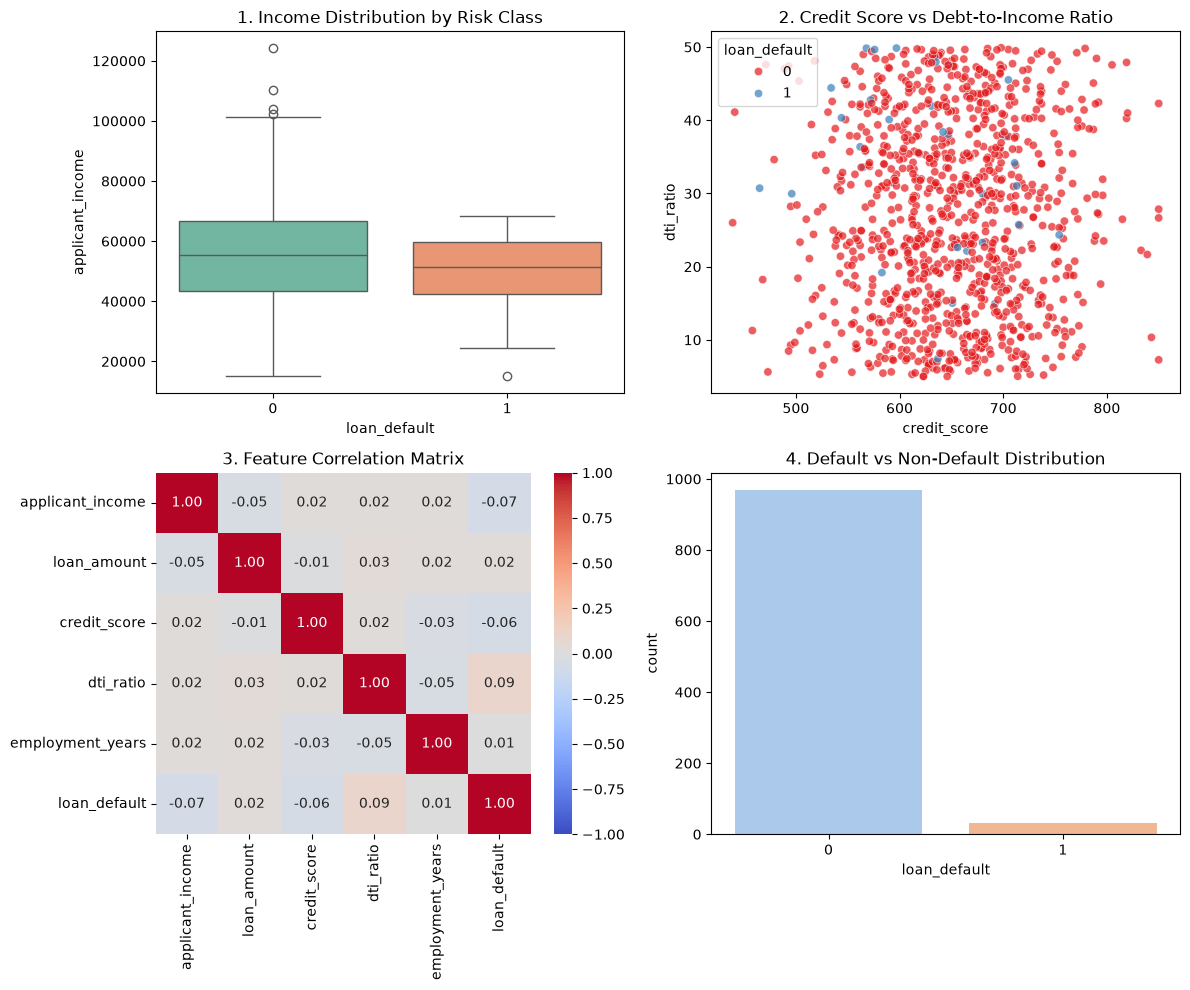

In [18]:
# ==============================================================================
# STEP 2: STATISTICAL MODELING & EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================
print("\n=== STEP 2: STATISTICAL SUMMARY ===")
print(df.describe().T[["mean", "std", "min", "50%", "max"]])

print("\nTarget Class Balance (0 = Non-Default, 1 = Default):")
print(df["loan_default"].value_counts(normalize=True) * 100)

# Statistical EDA Visualizations
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Feature Distribution (Income vs Loan Default)
sns.boxplot(
    data=df, 
    x="loan_default",        # Keep your original x variable
    y="applicant_income", 
    hue="loan_default",      # Assign the same variable from x to hue
    ax=axes[0, 0], 
    palette="Set2",
    legend=False            # Turn off the legend
)
axes[0, 0].set_title("1. Income Distribution by Risk Class")

# 2. Risk Factors Interaction (Credit Score vs DTI Ratio)
sns.scatterplot(
    data=df,
    x="credit_score",
    y="dti_ratio",
    hue="loan_default",
    palette="Set1",
    ax=axes[0, 1],
    alpha=0.7,
)
axes[0, 1].set_title("2. Credit Score vs Debt-to-Income Ratio")

# 3. Multicollinearity Assessment (Correlation Heatmap)
sns.heatmap(
    df.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 0], vmin=-1, vmax=1
)
axes[1, 0].set_title("3. Feature Correlation Matrix")

# 4. Class Balance Plot
sns.countplot(
    data=df, 
    x="loan_default", 
    hue="loan_default",  # Assign the x variable to hue
    legend=False,        # Turn off the legend    
    ax=axes[1, 1], 
    palette="pastel")
axes[1, 1].set_title("4. Default vs Non-Default Distribution")

plt.tight_layout()
plt.show()

In [19]:
# ==============================================================================
# STEP 3: PREPROCESSING & FEATURE ENGINEERING
# ==============================================================================
X = df.drop(columns=["loan_default"])
y = df["loan_default"]

# Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling (Crucial for distance/gradient based algorithms like Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
# ==============================================================================
# STEP 4: MACHINE LEARNING MODELING & COMPARISON
# ==============================================================================
# Model A: Logistic Regression (Interpretable Statistical Classifier)
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Model B: Random Forest Classifier (Non-linear Tree Ensemble)
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_clf.fit(X_train, y_train)

# Risk Probability Scoring
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_clf.predict_proba(X_test)[:, 1]

# Predictions based on standard 0.50 cutoff
y_pred_lr = (y_prob_lr >= 0.50).astype(int)
y_pred_rf = (y_prob_rf >= 0.50).astype(int)

print("\n=== STEP 4: MODEL EVALUATION REPORTS ===")
print("--- Logistic Regression ---")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("--- Random Forest Classifier ---")
print(classification_report(y_test, y_pred_rf, zero_division=0))  # Fix: Added zero_division=0 to suppress the warning and set undefined precision to 0


=== STEP 4: MODEL EVALUATION REPORTS ===
--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       194
           1       0.00      0.00      0.00         6

    accuracy                           0.97       200
   macro avg       0.48      0.50      0.49       200
weighted avg       0.94      0.97      0.96       200

--- Random Forest Classifier ---
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       194
           1       0.00      0.00      0.00         6

    accuracy                           0.97       200
   macro avg       0.48      0.50      0.49       200
weighted avg       0.94      0.97      0.96       200



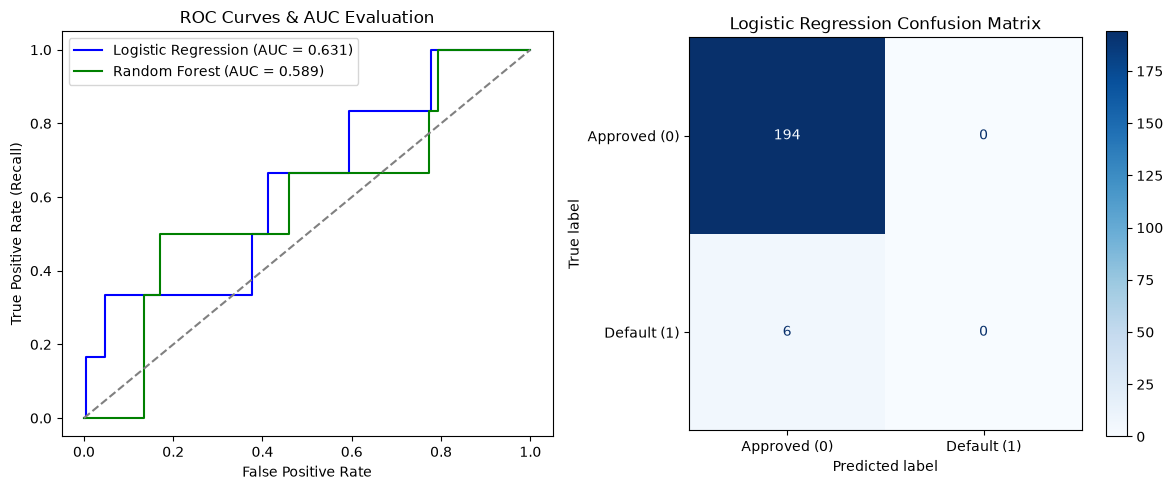

Logistic Regression Gini Coefficient: 0.263


In [21]:
# ==============================================================================
# STEP 5: VISUAL DIAGNOSTICS & THRESHOLD DECISION MAKING
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. ROC-AUC Curve Analysis
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)

axes[0].plot(
    fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})", color="blue"
)
axes[0].plot(
    fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})", color="green"
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curves & AUC Evaluation")
axes[0].legend()

# 2. Confusion Matrix for Selected Banking Model (Logistic Regression)
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(
    cm_lr, display_labels=["Approved (0)", "Default (1)"]
).plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

# Calculating Gini Coefficient
gini_lr = 2 * auc_lr - 1
print(f"Logistic Regression Gini Coefficient: {gini_lr:.3f}")